# Surrogate models
Diffusion coefficients, adsorption capacities and ethylene pore concentration. Run from `examples/`.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

## Diffusion

C:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator LinearRegression from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


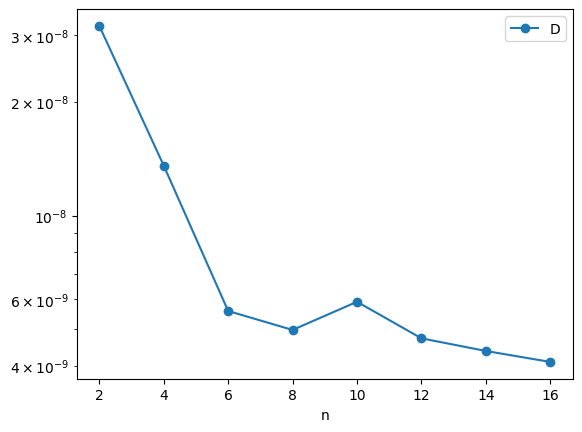

In [2]:
diff = joblib.load('../data/processed/diffusion_extrap_model.pkl')
df = pd.DataFrame({'n': [2, 4, 6, 8, 10, 12, 14, 16], 'temperature': [300] * 8})
df['D'] = diff.predict(df)
df.plot(x='n', y='D', marker='o', logy=True);

## Adsorption (kNN)

C:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator KNeighborsRegressor from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


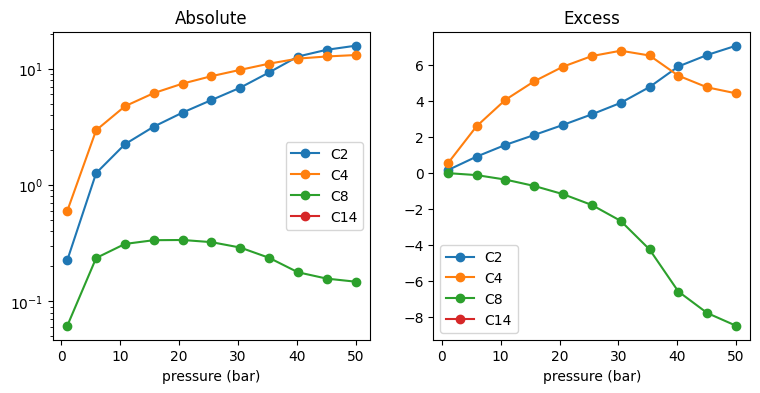

In [3]:
ads = joblib.load('../data/processed/knn_adsorption_slope_model.pkl')
X = pd.DataFrame(list(product(np.linspace(1, 50, 11), [300, 420, 510], [2, 4, 8, 14], [0, 1])),
                 columns=['pressure_bar', 'temperature', 'n', 'adsorption_type_num'])  # type: 0 absolute, 1 excess
X['adsorption'] = ads.predict(X)
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for t, ax in zip([0, 1], axs):
    for n, g in X.query('temperature==510 and adsorption_type_num==@t').groupby('n'):
        ax.plot(g.pressure_bar, g.adsorption, marker='o', label=f'C{n}')
    ax.set_title(['Absolute', 'Excess'][t]); ax.set_xlabel('pressure (bar)'); ax.legend()
axs[0].set_yscale('log')

## Ethylene pore concentration (Langmuir fit)

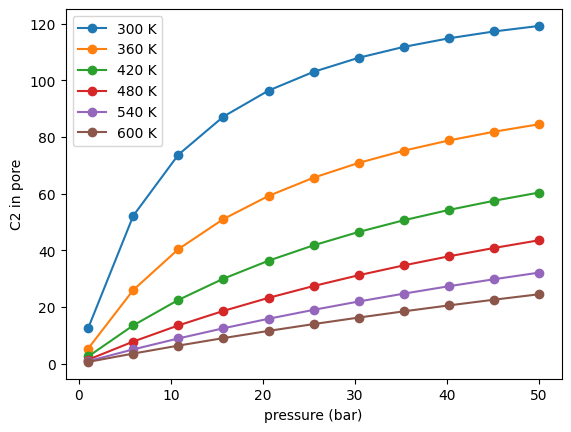

In [4]:
c2 = joblib.load('../data/adsorption/pt_poly_model.pkl')
p = np.linspace(1, 50, 11)
for T in range(300, 601, 60):
    plt.plot(p, c2.predict_absolute(p * 101325, np.full_like(p, T)), marker='o', label=f'{T} K')
plt.xlabel('pressure (bar)'); plt.ylabel('C2 in pore'); plt.legend();